In [1]:
%load_ext autoreload
%autoreload 2

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

In [2]:
import numpy as np
import matplotlib
import seaborn as sns
import matplotlib.patches as mpatches
import json
import sys
import os

from matplotlib import pyplot as plt
from matplotlib.ticker import AutoMinorLocator
from pesummary.io import read
from pesummary.core.plots.bounded_1d_kde import bounded_1d_kde as Bounded_1d_kde
from corner import hist2d

sys.path.append("./aux_data")
import utils_o3b

matplotlib.rcParams.update(matplotlib.rcParamsDefault)

matplotlib.style.use("paper.style")
plt.rcParams['font.sans-serif'] = [ 'Helvetica', 'Nimbus Sans', 'FreeSans' ]
plt.rcParams['font.serif'] = [ 'Times', 'Nimbus Roman', 'FreeSerif' ]
plt.rcParams['font.family'] = 'serif'
plt.rcParams['mathtext.fontset'] = 'stix'

sns.set_context("paper", font_scale=2.5, rc={"axes.labelsize":40})

/home/lorenzo.pompili/.conda/envs/igwn-tgr-data-release/lib/python3.10/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.7.3' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/home/lorenzo.pompili/.conda/envs/igwn-tgr-data-release/lib/python3.10/site-packages/gwpy/time/__init__.py:36: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  from lal import LIGOTime

In [3]:
# A list of events
event_list = [
    "GW150914",
    "GW170104",
    "S190519bj",
    "S190521r",
    "S190630ag",
    "S190828j",
    "S190910s",
    "S191109d",
    "S200129m",
    "S200208q",
    "S200224ca",
    "S200311bg",
    "S230628ax",
    "S230914ak",
    "S230927be",
    "S231028bg",
    "S231102w",
    "S231206cc",
    "S231226av",
]

In [4]:
# median (detector-frame) total mass from:
# Table 1 in https://dcc.ligo.org/public/0122/P1500218/014/PhysRevLett.116.241102.pdf
# Table 1 in https://journals.aps.org/prl/pdf/10.1103/PhysRevLett.118.221101, and
# Table 1 in https://arxiv.org/pdf/2010.14529.pdf
# Draft of GWTC-4 catalog results paper

mtotal_dict = json.load(open("./aux_data/dict_det_masses.json"))

cmap = plt.cm.coolwarm
norm = matplotlib.colors.TwoSlopeNorm(
    vcenter=100.0, vmin=40.0, vmax=160.0
)  # Updated wrt O3b

alpha = 0.2

# Prior used for each event
# All the events use a prior on both domega220 and dtau220: [-0.8,2.0] ...
prior_dict = {
    "dtau_220-min": dict(zip(event_list, -0.8 * np.ones(len(event_list)))),
    "dtau_220-max": dict(zip(event_list, 2.0 * np.ones(len(event_list)))),
    "domega_220-min": dict(zip(event_list, -0.8 * np.ones(len(event_list)))),
    "domega_220-max": dict(zip(event_list, 2.0 * np.ones(len(event_list)))),
}

# ... except S1901109d and S200208q, which use domega220-max=4, and dtau220-max=4
# So for these two events, use explicitly set the prior:
for event in ["S191109d", "S200208q"]:
    prior_dict["domega_220-max"][event] = 4.0
    prior_dict["dtau_220-max"][event] = 4.0

# Parameters to be visualized
params = ["domega220", "dtau220"]

In [5]:
event_map = {
    "GW150914": "GW150914_095045",
    "GW170104": "GW170104_101158",
    "S190519bj": "GW190519_153544",
    "S190521r": "GW190521_074359",
    "S190630ag": "GW190630_185205",
    "S190828j": "GW190828_063405",
    "S191109d": "GW191109_010717",
    "S190910s": "GW190910_112807",
    "S200129m": "GW200129_065458",
    "S200208q": "GW200208_130117",
    "S200224ca": "GW200224_222234",
    "S200311bg": "GW200311_115853",
    "S230628ax": "GW230628_231200",
    "S230914ak": "GW230914_111401",
    "S230927be": "GW230927_153832",
    "S231028bg": "GW231028_153006",
    "S231102w": "GW231102_071736",
    "S231206cc": "GW231206_233901",
    "S231226av": "GW231226_101520",
}

In [6]:
# Update this path to point to files downloaded from the Zenodo data release
basedir = "/home/tgr.o4/O4a/o4a-tgr/pSEOB/new_metafiles_resample"

res_dict = dict()

for event in event_map.keys():
    result = read(f"{basedir}/pSEOB_{event_map[event]}_Prod0.h5")
    res_dict[event] = result

lal.MSUN_SI != Msun
__name__ = gwsurrogate.new.spline_evaluation
__package__= gwsurrogate.new


In [7]:
# Load samples first
sample_dict = {}
for param in params:
    sample_dict[param] = {}
    for event in event_list:
        sample_dict[param][event] = np.array(
            res_dict[event].samples_dict["pSEOBNRv5PHM-reweighted"][param]
        )

/home/lorenzo.pompili/.conda/envs/igwn-tgr-data-release/lib/python3.10/site-packages/numpy/core/_methods.py:236: RuntimeWarning: invalid value encountered in subtract
  x = asanyarray(arr - arrmean)


In [8]:
CORNER_KWARGS = dict(
    show_titles=False,
    plot_contours=True,
    plot_datapoints=False,
    plot_density=False,
    levels=([0.9, 0.9, 0.9, 0.9]),
)

In [9]:
hier_samps = np.load("./hierarchical/pSEOB/pseob_hier_pop.npz")
hier_samps_o3b = np.load("./hierarchical/pSEOB_GWTC3/pseob_hier_pop_GWTC3.npz")

domega220_comb = np.loadtxt("./joint/joint_posterior_results/domega_220_comb.dat")
dtau220_comb = np.loadtxt("./joint/joint_posterior_results/dtau_220_comb.dat")
domega220_comb_O3b = np.loadtxt("./joint/joint_posterior_results_GWTC3/domega_220_comb_GWTC3.dat")
dtau220_comb_O3b = np.loadtxt("./joint/joint_posterior_results_GWTC3/dtau_220_comb_GWTC3.dat")

domega220_hier = hier_samps["pop_domega_220"]
dtau220_hier = hier_samps["pop_dtau_220"]
domega220_hier_O3b = hier_samps_o3b["pop_domega_220"]
dtau220_hier_O3b = hier_samps_o3b["pop_dtau_220"]

/home/lorenzo.pompili/tgr/GWTC-4-data-release/o4a-tgr/prerelease/pseob/./aux_data/utils_o3b.py:837: UserWarning: linewidths is ignored by contourf
  ax.contourf(XS, YS, ZS, levels=l, **kwargs)


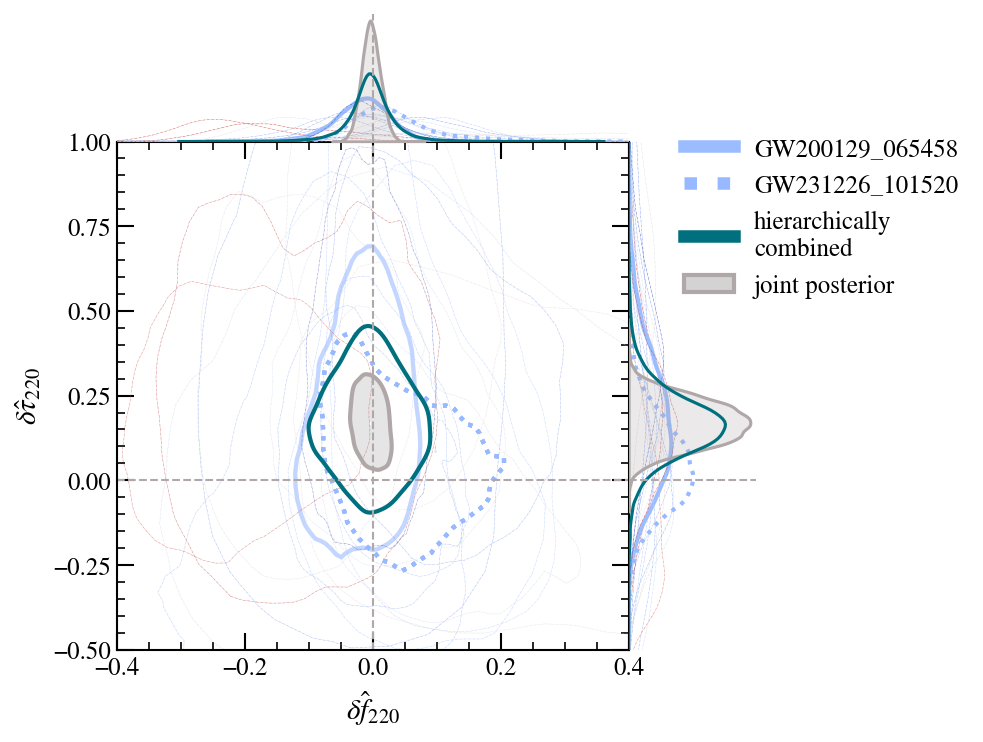

In [10]:
fig = plt.figure(figsize=(5.5, 5.5), dpi=200)
gs = fig.add_gridspec(ncols=2, nrows=2, width_ratios=[4, 1], height_ratios=[1, 4])

ax_joint = fig.add_subplot(gs[1, 0])
ax_df_220 = fig.add_subplot(gs[0, 0], sharex=ax_joint)
ax_dtau_220 = fig.add_subplot(gs[1, 1], sharey=ax_joint)
sns.despine(ax=ax_df_220)
sns.despine(ax=ax_dtau_220)
plt.subplots_adjust(hspace=0.0, wspace=0.0)

for event in event_list:

    c = cmap(norm(mtotal_dict[event]))

    if event in ["S200129m", "S231226av"]:
        lw = 2.0
        matplotlib.rcParams["lines.linewidth"] = 2.0
        matplotlib.rcParams["patch.linewidth"] = 2.0
        if event == "S231226av":
            ls = "dotted"
        elif event == "S200129m":
            ls = "solid"
    else:
        lw = 0.2
        matplotlib.rcParams["lines.linewidth"] = 0.2
        matplotlib.rcParams["patch.linewidth"] = 0.2
        ls = "dashdot"
        label = None

    sns.kdeplot(x=sample_dict["domega220"][event], ax=ax_df_220, lw=lw, color=c, ls=ls)
    sns.kdeplot(y=sample_dict["dtau220"][event], ax=ax_dtau_220, lw=lw, color=c, ls=ls)

    hist2d(
        ax=ax_joint,
        x=sample_dict["domega220"][event],
        y=sample_dict["dtau220"][event],
        color=c,
        quiet=True,
        bins=45,
        smooth=1.0,
        contour_kwargs={"linestyles": ls},
        no_fill_contours=True,
        **CORNER_KWARGS,
    )
    if event not in ["GW150914", "S200129m", "S231226av"]:
        for collection in ax_joint.collections:
            if hasattr(collection, "set_alpha"):
                collection.set_alpha(0.2)

sns.kdeplot(
    x=domega220_comb, ax=ax_df_220, color="#b0a8a8", lw=1.5, fill=True, zorder=2
)
sns.kdeplot(
    y=dtau220_comb, ax=ax_dtau_220, color="#b0a8a8", lw=1.5, fill=True, zorder=2
)

sns.kdeplot(x=domega220_hier, ax=ax_df_220, color="#00707e", lw=1.5)
sns.kdeplot(y=dtau220_hier, ax=ax_dtau_220, color="#00707e", lw=1.5)

sns.kdeplot(
    x=domega220_comb,
    y=dtau220_comb,
    levels=[0.1],
    color="#b0a8a8",
    ax=ax_joint,
    bw_adjust=1.5,
)
sns.kdeplot(
    x=domega220_hier,
    y=dtau220_hier,
    levels=[0.1],
    color="#00707e",
    ax=ax_joint,
    bw_adjust=1.5,
)

utils_o3b.kdeplot_2d_clevels_contourf(
    domega220_comb,
    dtau220_comb,
    levels=[0.90, 0.01],
    xlow=np.min(domega220_comb),
    xhigh=np.max(domega220_comb),
    ylow=np.min(dtau220_comb),
    yhigh=np.max(dtau220_comb),
    ax=ax_joint,
    linewidths=[0.1],
    colors=["k"],
    alpha=0.1,
)

df_220_min, df_220_max = -0.4, 0.4
dtau_220_min, dtau_220_max = -0.5, 1.0

tick_pos_x = np.linspace(df_220_min, df_220_max, num=5)
tick_pos_y = np.linspace(dtau_220_min, dtau_220_max, num=7)

ax_joint.set_xlabel(r"$\delta \hat{f}_{220}$", fontsize=14)
ax_joint.set_ylabel(r"$\delta \hat{\tau}_{220}$", fontsize=14)
ax_joint.set_xticks(tick_pos_x)
ax_joint.set_yticks(tick_pos_y)

ax_df_220.set_xlim(-0.4, 0.4)
ax_dtau_220.set_ylim(-0.5, 1.0)

linewidth = 1
ax_joint.xaxis.set_minor_locator(AutoMinorLocator())
ax_joint.yaxis.set_minor_locator(AutoMinorLocator())

tick_params = {
    "length": 4,
    "bottom": True,
    "left": True,
    "top": True,
    "right": True,
    "direction": "in",
    "zorder": 10,
}
major_tick_params = {**tick_params, "length": 8, "labelsize": 12}

for axis in ["x", "y"]:
    ax_joint.tick_params(axis=axis, which="minor", **tick_params)
    ax_joint.tick_params(axis=axis, which="major", **major_tick_params)

ax_joint.grid(visible=False)

ax_joint.axvline(0, ls="--", c="#b0a8a8", linewidth=linewidth)
ax_joint.axhline(0, ls="--", c="#b0a8a8", linewidth=linewidth)
ax_df_220.axvline(0, ls="--", c="#b0a8a8", linewidth=linewidth)
ax_dtau_220.axhline(0, ls="--", c="#b0a8a8", linewidth=linewidth)

ax_df_220.set_ylim(bottom=0.0)
ax_dtau_220.set_xlim(left=0.0)

ax_df_220.axis("off")
ax_dtau_220.axis("off")

ax_joint.legend(
    *ax_df_220.get_legend_handles_labels(),
    bbox_to_anchor=(-0.35, 1.0),  # Move legend outside to the left
    loc="upper left",
    frameon=False,
    prop={"size": 12},
    handlelength=3,
)


from matplotlib.lines import Line2D
from matplotlib.patches import Patch

c1 = cmap(norm(mtotal_dict["S200129m"]))
c2 = cmap(norm(mtotal_dict["S231226av"]))

custom_lines = [
    Line2D([0], [0], color=c1, lw=0.1, linestyle="-", label=r"GW200129_065458"),
    Line2D([0], [0], color=c2, lw=0.1, linestyle=":", label=r"GW231226_101520"),
    Line2D(
        [0],
        [0],
        color="#00707e",
        lw=0.1,
        linestyle="-",
        label="hierarchically\ncombined",
    ),
    Patch(facecolor="lightgray", edgecolor="#b0a8a8", label="joint posterior"),
]

ax_joint.legend(
    handles=custom_lines,
    loc="center left",
    bbox_to_anchor=(1.05, 0.85),
    frameon=False,
    prop={"size": 12},
    handlelength=2,
)

os.makedirs("./plots", exist_ok=True)
plt.savefig("./plots/rin_pseob_results.pdf", bbox_inches="tight")
plt.savefig("./plots/rin_pseob_results.png", bbox_inches="tight")

fig.set_dpi(150)

## Plot bounds

In [11]:
matplotlib.rcParams.update(matplotlib.rcParamsDefault)

matplotlib.style.use("paper.style")
plt.rcParams['font.sans-serif'] = [ 'Helvetica', 'Nimbus Sans', 'FreeSans' ]
plt.rcParams['font.serif'] = [ 'Times', 'Nimbus Roman', 'FreeSerif' ]
plt.rcParams['font.family'] = 'serif'
plt.rcParams['mathtext.fontset'] = 'stix'

# further tune some rcParams
plt.rcParams.update(
    {
        "ytick.labelsize": 0.6 * utils_o3b.fs_label,
        "legend.fontsize": 0.8 * utils_o3b.fs_label,
    }
)

# Specify some aesthetic colours...
dodgerblue = "#1E90FF"
lawngreen = "#7CFC00"
blueviolet = "#8A2BE2"
caltechorange = "#FF6C0C"
walesaway = "#293133"
waleshome = "#ff0038"
uniwienblue = "#006699"
uniwiengrey = "#666666"
emeraldgreen = "#50C878"
tanzaniagreen = "#1eb53a"
grey3 = "#565759"
grey1 = "#C0BEC6"
grey2 = "#AAA7B0"

kwargs = {
    "GWTC-3 (Phenom)": {
        "markeredgewidth": 2,
        "markersize": 12,
        "alpha": 0.8,
        "marker": 6,
        "color": "0.6",
        "ls": "",
    },
    "GWTC-3 (SEOB)": {
        "markeredgewidth": 1,
        "markersize": 12,
        "alpha": 0.8,
        "marker": 6,
        "markeredgecolor": "#00707e",
        "markerfacecolor": "none",
        "ls": "",
    },
    "GWTC-2 (Phenom)": {
        "markeredgewidth": 2,
        "markersize": 12,
        "alpha": 0.8,
        "marker": 7,
        "color": "0.6",
        "ls": "",
    },
    "GWTC-2 (SEOB)": {
        "markeredgewidth": 1,
        "markersize": 12,
        "alpha": 0.8,
        "marker": 7,
        "markeredgecolor": "#00707e",
        "markerfacecolor": "none",
        "ls": "",
    },
    "GWTC-1 (Phenom)": {
        "markeredgewidth": 0.5,
        "markersize": 15,
        "marker": ".",
        "color": waleshome,
        "markeredgecolor": "w",
        "ls": "",
    },
    "GW170817 (Phenom)": {
        "markeredgewidth": 0.5,
        "markersize": 15,
        "marker": ".",
        "color": dodgerblue,
        "markeredgecolor": "w",
        "ls": "",
    },
    "event": {
        "marker": "_",
        "ls": "",
        "markersize": 20,
        "alpha": 0.5,
        "markeredgewidth": 3,
    },
    "GW150914": {
        "marker": "D",
        "ls": "",
        "markersize": 5,
        "alpha": 0.8,
        "markeredgewidth": 2,
        #'markerfacecolor': 'none',
    },
    "S200129m": {
        "marker": "s",
        "ls": "",
        "markersize": 5,
        "alpha": 0.5,
        "markeredgewidth": 2,
        #'markerfacecolor': 'none',
    },
}

In [12]:
def kde_helper(samples, xlow=None, xhigh=None):
    # Initialize bounded KDE
    if xlow is None:
        xlow = np.amin(samples)
    if xhigh is None:
        xhigh = np.amax(samples)
    kde = Bounded_1d_kde(samples, xlow=xlow, xhigh=xhigh)
    pts = np.linspace(xlow, xhigh, num=500)
    pdf = kde(pts)

    return pts, pdf

In [13]:
df_220_comb_pts, df_220_comb_pdf = kde_helper(domega220_comb)
dtau_220_comb_pts, dtau_220_comb_pdf = kde_helper(dtau220_comb)
df_220_hier_pts, df_220_hier_pdf = kde_helper(domega220_hier)
dtau_220_hier_pts, dtau_220_hier_pdf = kde_helper(dtau220_hier)

/home/lorenzo.pompili/.conda/envs/igwn-tgr-data-release/lib/python3.10/site-packages/pesummary/utils/decorators.py:288: UserWarning: pesummary.core.plots.bounded_1d_kde.bounded_1d_kde has changed to pesummary.utils.bounded_1d_kde.bounded_1d_kde. This may not be supported in future releases. Please update.
  warnings.warn(warning)


Event 	 Total Mass 	 CI:domega220 	 CI:dtau220
GW150914 	 71 	 0.17 	 0.64
GW170104 	 60 	 0.30 	 1.62
S190519bj 	 155 	 0.33 	 0.96
S190521r 	 93 	 0.29 	 0.66
S190630ag 	 70 	 0.33 	 1.09
S190828j 	 80 	 0.26 	 1.05
S190910s 	 102 	 0.23 	 1.14
S191109d 	 141 	 1.84 	 0.72
S200129m 	 75 	 0.14 	 0.67
S200208q 	 91 	 1.30 	 1.12
S200224ca 	 95 	 0.27 	 0.83
S200311bg 	 76 	 0.26 	 1.94
S230628ax 	 62 	 0.28 	 0.87
S230914ak 	 96 	 0.26 	 0.88
S230927be 	 39 	 0.16 	 0.89
S231028bg 	 151 	 0.30 	 0.60
S231102w 	 105 	 0.61 	 0.80
S231206cc 	 66 	 0.21 	 0.65
S231226av 	 74 	 0.22 	 0.45
Joint lklhd 	 -- 	 0.05 	 0.21
Hier 	 -- 	 0.12 	 0.35
Joint lklhd (O3b) 	 -- 	 0.06 	 0.28
Hier (O3b) 	 -- 	 0.13 	 0.53


/local/lorenzo.pompili/ipykernel_3773621/2215700435.py:151: MatplotlibDeprecationWarning: Unable to determine Axes to steal space for Colorbar. Using gca(), but will raise in the future. Either provide the *cax* argument to use as the Axes for the Colorbar, provide the *ax* argument to steal space from it, or add *mappable* to an Axes.
  cbar = plt.colorbar(sm, ticks=np.arange(45, 165, 10))


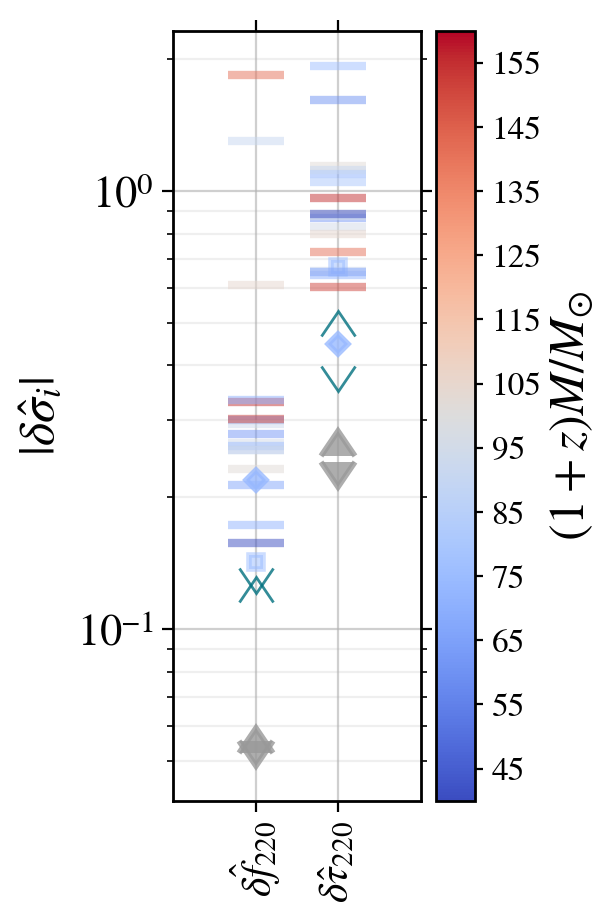

In [14]:
print(f"Event \t Total Mass \t CI:domega220 \t CI:dtau220")

fig = plt.figure(figsize=(2, 5), dpi=200)
ax = fig.add_subplot(111)

for event in event_list:

    domega220_pts, domega220_pdf = kde_helper(
        sample_dict["domega220"][event],
        xlow=prior_dict["domega_220-min"][event],
        xhigh=prior_dict["domega_220-max"][event],
    )
    dtau220_pts, dtau220_pdf = kde_helper(
        sample_dict["dtau220"][event],
        xlow=prior_dict["dtau_220-min"][event],
        xhigh=prior_dict["dtau_220-max"][event],
    )

    domega220_left, domega220_right = utils_o3b.get_sym_interval_from_pdf(
        domega220_pdf, domega220_pts, p=0.9, normalize=True
    )
    dtau220_left, dtau220_right = utils_o3b.get_sym_interval_from_pdf(
        dtau220_pdf, dtau220_pts, p=0.9, normalize=True
    )

    c = cmap(norm(mtotal_dict[event]))

    print(
        f"{event} \t {mtotal_dict[event]} \t {domega220_right - domega220_left:.2f} \t {dtau220_right - dtau220_left:.2f}"
    )

    if event == "S231226av":
        ax.semilogy(0, domega220_right - domega220_left, c=c, **kwargs["GW150914"])
        ax.semilogy(1, dtau220_right - dtau220_left, c=c, **kwargs["GW150914"])
    elif event == "S200129m":
        ax.semilogy(0, domega220_right - domega220_left, c=c, **kwargs["S200129m"])
        ax.semilogy(1, dtau220_right - dtau220_left, c=c, **kwargs["S200129m"])
    else:
        ax.semilogy(0, domega220_right - domega220_left, c=c, **kwargs["event"])
        ax.semilogy(1, dtau220_right - dtau220_left, c=c, **kwargs["event"])


# condifence intervals on combined posteriors
domega220_comb_left, domega220_comb_right = utils_o3b.get_sym_interval_from_pdf(
    df_220_comb_pdf, df_220_comb_pts, p=0.9, normalize=True
)
dtau220_comb_left, dtau220_comb_right = utils_o3b.get_sym_interval_from_pdf(
    dtau_220_comb_pdf, dtau_220_comb_pts, p=0.9, normalize=True
)
ax.semilogy(
    0,
    domega220_comb_right - domega220_comb_left,
    **kwargs["GWTC-2 (Phenom)"],
    label="joint\nlikelihood",
)
ax.semilogy(1, dtau220_comb_right - dtau220_comb_left, **kwargs["GWTC-2 (Phenom)"])

print(
    f"Joint lklhd \t -- \t {domega220_comb_right - domega220_comb_left:.2f} \t {dtau220_comb_right - dtau220_comb_left:.2f}"
)

# condifence intervals on hierarchical posteriors
domega220_hier_left, domega220_hier_right = utils_o3b.get_sym_interval_from_pdf(
    df_220_hier_pdf, df_220_hier_pts, p=0.9, normalize=True
)
dtau220_hier_left, dtau220_hier_right = utils_o3b.get_sym_interval_from_pdf(
    dtau_220_hier_pdf, dtau_220_hier_pts, p=0.9, normalize=True
)
ax.semilogy(
    0,
    domega220_hier_right - domega220_hier_left,
    **kwargs["GWTC-2 (SEOB)"],
    label="hierarchically\ncombined",
)
ax.semilogy(1, dtau220_hier_right - dtau220_hier_left, **kwargs["GWTC-2 (SEOB)"])

print(
    f"Hier \t -- \t {domega220_hier_right - domega220_hier_left:.2f} \t {dtau220_hier_right - dtau220_hier_left:.2f}"
)


# domega_220
df_220_comb_pts_O3b, df_220_comb_pdf_O3b = kde_helper(domega220_comb_O3b)
# dtau_220
dtau_220_comb_pts_O3b, dtau_220_comb_pdf_O3b = kde_helper(dtau220_comb_O3b)

# condifence intervals on combined posteriors
domega220_comb_left_O3b, domega220_comb_right_O3b = utils_o3b.get_sym_interval_from_pdf(
    df_220_comb_pdf_O3b, df_220_comb_pts_O3b, p=0.9, normalize=True
)
dtau220_comb_left_O3b, dtau220_comb_right_O3b = utils_o3b.get_sym_interval_from_pdf(
    dtau_220_comb_pdf_O3b, dtau_220_comb_pts_O3b, p=0.9, normalize=True
)
ax.semilogy(
    0,
    domega220_comb_right_O3b - domega220_comb_left_O3b,
    **kwargs["GWTC-3 (Phenom)"],
    label="joint\nlikelihood",
)
ax.semilogy(
    1, dtau220_comb_right_O3b - dtau220_comb_left_O3b, **kwargs["GWTC-3 (Phenom)"]
)

print(
    f"Joint lklhd (O3b) \t -- \t {domega220_comb_right_O3b - domega220_comb_left_O3b:.2f} \t {dtau220_comb_right_O3b - dtau220_comb_left_O3b:.2f}"
)

# Plot the hierarchical results
# domega_220
df_220_hier_pts_O3b, df_220_hier_pdf_O3b = kde_helper(domega220_hier_O3b)
# dtau_220
dtau_220_hier_pts_O3b, dtau_220_hier_pdf_O3b = kde_helper(dtau220_hier_O3b)

domega220_hier_left_O3b, domega220_hier_right_O3b = utils_o3b.get_sym_interval_from_pdf(
    df_220_hier_pdf_O3b, df_220_hier_pts_O3b, p=0.9, normalize=True
)
dtau220_hier_left_O3b, dtau220_hier_right_O3b = utils_o3b.get_sym_interval_from_pdf(
    dtau_220_hier_pdf_O3b, dtau_220_hier_pts_O3b, p=0.9, normalize=True
)
ax.semilogy(
    0,
    domega220_hier_right_O3b - domega220_hier_left_O3b,
    **kwargs["GWTC-3 (SEOB)"],
    label="hierarchically\ncombined",
)
ax.semilogy(
    1, dtau220_hier_right_O3b - dtau220_hier_left_O3b, **kwargs["GWTC-3 (SEOB)"]
)

print(
    f"Hier (O3b) \t -- \t {domega220_hier_right_O3b - domega220_hier_left_O3b:.2f} \t {dtau220_hier_right_O3b - dtau220_hier_left_O3b:.2f}"
)


ax.set_xticks(np.arange(len(params)))
ax.set_xticklabels(
    [r"$\delta \hat{f}_{220}$", r"$\delta \hat{\tau}_{220}$"], fontsize=15, rotation=90
)
ax.tick_params(axis="y", labelsize=16)
ax.tick_params(axis="x", which="minor", bottom=False, top=False)
ax.set_ylabel("$|\delta \hat{\sigma}_i|$", fontsize=18)
ax.grid(which="major", axis="both", linestyle="-", alpha=0.6)
ax.grid(which="minor", linestyle="-", alpha=0.2, axis="y")

# Set x- and y-limits
ax.set_xlim(-1.0, 2.0)

# add colorbar
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ticks=np.arange(45, 165, 10))
cbar.ax.set_yticklabels(cbar.ax.get_yticklabels(), fontsize=12)
cbar.ax.tick_params("y", length=3, which="major")
cbar.ax.tick_params("y", which="minor", left=False, right=False)
cbar.set_label(r"$ (1 + z) M / M_{\odot}$", fontsize=18, labelpad=2.5)

plt.savefig(
    "./plots/rin_all_events_bounds_fix.pdf",
    bbox_inches="tight",
)
plt.savefig(
    "./plots/rin_all_events_bounds_fix.png",
    bbox_inches="tight",
)

plt.show()